# Lab 1: Data Visualization, Preprocessing, and Statistical Analysis

**Name:** Todd Simonson
**Course:** MSCS-634: Advanced Big Data and Data Mining
**Instructor:** Dr. Satish Penmatsa
**Assignment:** Lab 1: Data Visualization, Data Preprocessing, and Statistical Analysis

**Dataset:** NOAA Global Historical Climatology Network Daily (GHCN-Daily), station USW00093037, Colorado Springs Municipal Airport, Colorado. Daily observations from January 1, 2015 through December 31, 2024.
Source: https://www.ncei.noaa.gov/data/global-historical-climatology-network-daily/access/USW00093037.csv

## Step 1: Data Collection

### Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

Matplotlib is building the font cache; this may take a moment.


### Load the dataset

The raw NOAA file covers the full history of the station. It is loaded into a DataFrame and filtered to a ten-year window (2015 through 2024).

In [2]:
raw = pd.read_csv('data/USW00093037.csv', low_memory=False)
raw['DATE'] = pd.to_datetime(raw['DATE'])

df = raw[(raw['DATE'] >= '2015-01-01') & (raw['DATE'] <= '2024-12-31')].copy()
df = df.reset_index(drop=True)

print('full station history:', raw.shape)
print('2015-2024 window:   ', df.shape)

full station history: (30738, 108)
2015-2024 window:    (3653, 108)


### Convert units

GHCN-Daily stores values in tenths of metric units (temperature in tenths of °C, precipitation in tenths of mm, wind in tenths of m/s). The core measurements are converted to readable units: °F, inches, and mph. Snow and snow depth are stored in whole millimeters and are converted to inches.

In [3]:
# temperature: tenths of deg c -> deg f
df['TMAX_F'] = (df['TMAX'] / 10) * 9 / 5 + 32
df['TMIN_F'] = (df['TMIN'] / 10) * 9 / 5 + 32

# precipitation: tenths of mm -> inches, snow and depth: mm -> inches
df['PRCP_IN'] = df['PRCP'] / 254
df['SNOW_IN'] = df['SNOW'] / 25.4
df['SNWD_IN'] = df['SNWD'] / 25.4

# wind: tenths of m/s -> mph
df['AWND_MPH'] = (df['AWND'] / 10) * 2.23694
df['WSF5_MPH'] = (df['WSF5'] / 10) * 2.23694

# calendar fields for grouping
df['YEAR'] = df['DATE'].dt.year
df['MONTH'] = df['DATE'].dt.month
df['SEASON'] = df['MONTH'].map({12: 'Winter', 1: 'Winter', 2: 'Winter',
                                3: 'Spring', 4: 'Spring', 5: 'Spring',
                                6: 'Summer', 7: 'Summer', 8: 'Summer',
                                9: 'Fall', 10: 'Fall', 11: 'Fall'})

### First five rows

In [4]:
df[['DATE', 'NAME', 'TMAX_F', 'TMIN_F', 'PRCP_IN', 'SNOW_IN', 'SNWD_IN', 'AWND_MPH', 'RHAV', 'SEASON']].head()

,DATE,NAME,TMAX_F,TMIN_F,PRCP_IN,SNOW_IN,SNWD_IN,AWND_MPH,RHAV,SEASON
0,2015-01-01,"COLORADO SPRINGS MUNICIPAL AIRPORT, CO US",24.26,2.12,0.090551,2.007874,0.000000,8.500372,69.0,Winter
1,2015-01-02,"COLORADO SPRINGS MUNICIPAL AIRPORT, CO US",35.96,12.20,0.000000,0.000000,1.968504,5.816044,69.0,Winter
2,2015-01-03,"COLORADO SPRINGS MUNICIPAL AIRPORT, CO US",41.00,9.14,0.000000,0.000000,1.968504,13.197946,62.0,Winter
3,2015-01-04,"COLORADO SPRINGS MUNICIPAL AIRPORT, CO US",30.20,3.20,0.000000,0.000000,1.181102,3.355410,71.0,Winter
4,2015-01-05,"COLORADO SPRINGS MUNICIPAL AIRPORT, CO US",60.98,19.22,0.000000,0.000000,0.000000,9.618842,48.0,Winter


## Step 2: Data Visualization

### Line plot: daily high and low temperature over time

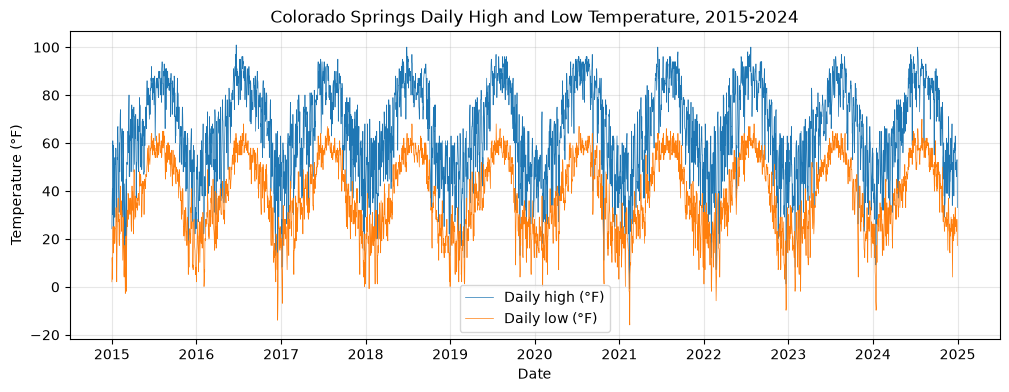

In [5]:
plt.figure(figsize=(12, 4))
plt.plot(df['DATE'], df['TMAX_F'], linewidth=0.5, label='Daily high (°F)')
plt.plot(df['DATE'], df['TMIN_F'], linewidth=0.5, label='Daily low (°F)')
plt.xlabel('Date')
plt.ylabel('Temperature (°F)')
plt.title('Colorado Springs Daily High and Low Temperature, 2015-2024')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Insight:** The plot shows ten clear annual cycles. Daily highs peak in the upper 90s °F each summer (the record in this window is 100.94 °F on June 21, 2016), and daily lows fall to around 0 °F or below in most winters. The two lines stay far apart all year: the average gap between the daily high and low is 27.64 °F, which is typical of a dry, high-elevation station (the airport sits at 1,884 m, about 6,180 ft). The sharpest downward spikes are short cold snaps, such as February 14, 2021, when the high only reached −0.76 °F.

### Histogram: distribution of daily high temperature

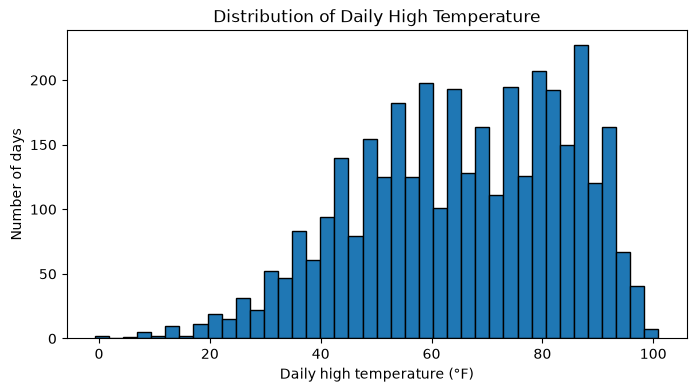

In [6]:
plt.figure(figsize=(8, 4))
plt.hist(df['TMAX_F'], bins=40, edgecolor='black')
plt.xlabel('Daily high temperature (°F)')
plt.ylabel('Number of days')
plt.title('Distribution of Daily High Temperature')
plt.show()

**Insight:** The distribution is not a single bell curve. Most days fall between about 45 °F and 90 °F, with a broad cool-season hump around 45 to 60 °F and a taller warm-season hump around 80 to 90 °F, because a full year mixes very different seasons into one column. The left tail is long (skewness of −0.39): only 155 days had a high below freezing, but those days stretch down to −0.76 °F. That tail pulls the mean (65.47 °F) slightly below the median (66.92 °F).

### Box plot: daily high temperature by month

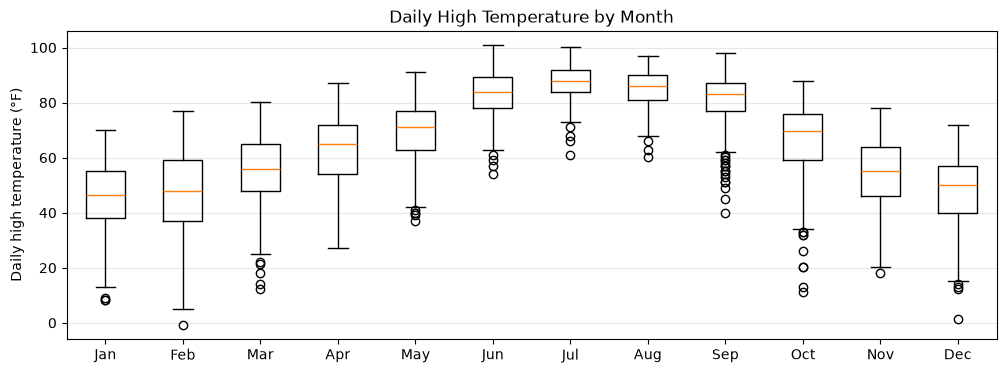

In [7]:
monthly = [df.loc[df['MONTH'] == m, 'TMAX_F'] for m in range(1, 13)]
labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

plt.figure(figsize=(12, 4))
plt.boxplot(monthly, tick_labels=labels)
plt.ylabel('Daily high temperature (°F)')
plt.title('Daily High Temperature by Month')
plt.grid(axis='y', alpha=0.3)
plt.show()

**Insight:** Summer highs are both warmer and far more consistent than winter highs. July has the highest median (88.0 °F) and the smallest spread (standard deviation 6.3 °F), while February has a standard deviation of 15.1 °F, more than twice as large. The outlier circles in June through October are all on the low side; they are cool, stormy days and early-season snow, not data errors. This is also why the IQR test on the full temperature column in Step 3.2 flags only 7 days: a 45 °F high is unusual in July but normal in March.

### Scatter plot: daily high vs. daily low temperature

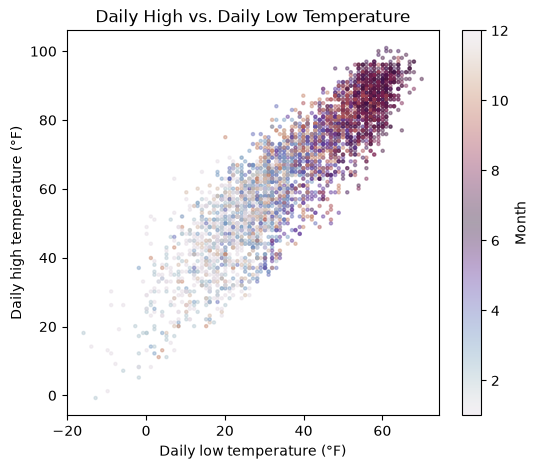

In [8]:
plt.figure(figsize=(6, 5))
plt.scatter(df['TMIN_F'], df['TMAX_F'], s=5, alpha=0.4, c=df['MONTH'], cmap='twilight')
plt.colorbar(label='Month')
plt.xlabel('Daily low temperature (°F)')
plt.ylabel('Daily high temperature (°F)')
plt.title('Daily High vs. Daily Low Temperature')
plt.show()

**Insight:** Daily high and low temperature have a strong positive linear relationship (r = 0.90 in the correlation matrix in Step 4.4). The color shading separates the seasons cleanly, with summer days in the upper right and winter days in the lower left. The vertical band at any given low temperature is about 30 to 40 °F wide, which shows how much the daily swing can vary from one day to the next.

### Bar chart: average monthly precipitation

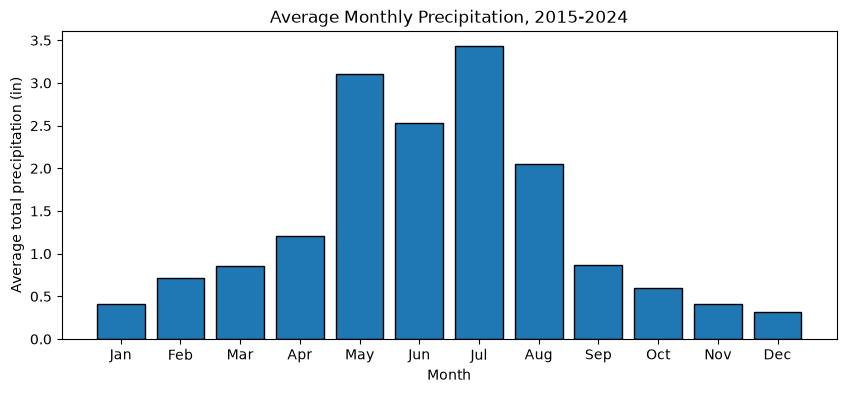

MONTH
1     0.41
2     0.71
3     0.85
4     1.21
5     3.10
6     2.53
7     3.44
8     2.05
9     0.86
10    0.59
11    0.41
12    0.32
Name: PRCP_IN, dtype: float64

In [9]:
# total precipitation per month for each year, then averaged across the ten years
monthly_precip = df.groupby(['YEAR', 'MONTH'])['PRCP_IN'].sum().groupby('MONTH').mean()

plt.figure(figsize=(10, 4))
plt.bar(labels, monthly_precip.values, edgecolor='black')
plt.xlabel('Month')
plt.ylabel('Average total precipitation (in)')
plt.title('Average Monthly Precipitation, 2015-2024')
plt.show()

monthly_precip.round(2)

**Insight:** Precipitation is strongly seasonal. July (3.44 in) and May (3.10 in) are the wettest months and December (0.32 in) is the driest. May through August together average 11.12 in, about 67% of the mean annual total of 16.49 in. Most of the year's moisture arrives as late-spring storms and summer afternoon thunderstorms, while winter snow contains little liquid water. Annual totals also vary widely, from 9.92 in (2020) to 25.48 in (2023).

### Pie chart: share of days with measurable precipitation, by season

SEASON
Summer    346
Spring    251
Winter    158
Fall      151
Name: count, dtype: int64


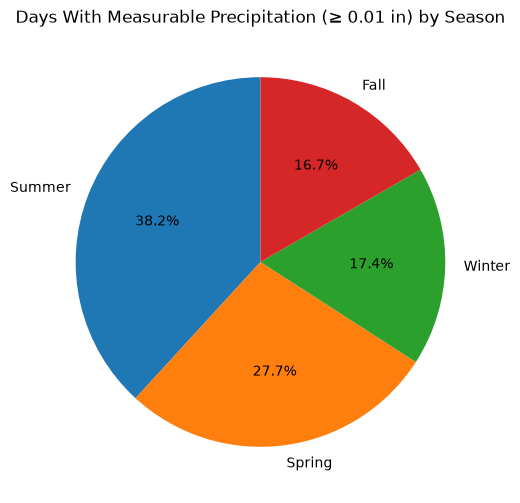

In [10]:
wet_days = df[df['PRCP_IN'] >= 0.01]['SEASON'].value_counts()
print(wet_days)

plt.figure(figsize=(6, 6))
plt.pie(wet_days, labels=wet_days.index, autopct='%1.1f%%', startangle=90)
plt.title('Days With Measurable Precipitation (≥ 0.01 in) by Season')
plt.show()

**Insight:** Measurable precipitation (at least 0.01 in) fell on 906 of the 3,653 days, or about 1 day in 4. Summer accounts for the largest share of those days (346 days, 38.2%), followed by spring (27.7%). Winter (17.4%) and fall (16.7%) are nearly tied. The pie chart and the bar chart agree: summer is wetter both in how often it rains and in how much falls.

## Step 3: Data Preprocessing

### 3.1 Handling Missing Values

#### Detect and report missing values

The `_ATTRIBUTES` columns hold NOAA quality and source flags rather than measurements, so they are set aside for this check.

In [11]:
measure_cols = [c for c in raw.columns if not c.endswith('_ATTRIBUTES')]
wx = df[measure_cols].copy()

missing = wx.isnull().sum()
report = pd.DataFrame({'missing': missing, 'percent': (missing / len(wx) * 100).round(1)})
report[report['missing'] > 0].sort_values('missing')

,missing,percent
WSF5,2,0.1
WDF5,2,0.1
RHMX,38,1.0
RHMN,38,1.0
RHAV,38,1.0
ADPT,48,1.3
AWBT,48,1.3
ASLP,51,1.4
ASTP,51,1.4
WT01,2826,77.4


The missing values fall into three groups, and each group needs a different treatment:

1. **Columns that are empty or almost empty** (for example `TAVG`, `TSUN`, `WESD`, `PGTM`). The station did not report these during this period, so there is nothing to recover.
2. **Weather-type flags** (`WT01` through `WT22`). NOAA records a 1 when an event such as fog or hail occurred and leaves the cell blank otherwise. A blank means "did not occur," not "unknown."
3. **Sensor gaps** in humidity, dew point, pressure, and peak gust (`RHAV`, `ADPT`, `ASLP`, `WSF5`, and related columns), with 2 to 51 missing days each.

#### Before: rows with missing humidity

In [12]:
gap_cols = ['DATE', 'RHAV', 'RHMN', 'RHMX', 'ADPT', 'AWBT', 'ASLP', 'ASTP', 'WSF5']
wx.loc[wx['RHAV'].isnull(), gap_cols]

,DATE,RHAV,RHMN,RHMX,ADPT,AWBT,ASLP,ASTP,WSF5
31,2015-02-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,134.0
32,2015-02-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,98.0
33,2015-02-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,116.0
34,2015-02-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,188.0
35,2015-02-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,94.0
36,2015-02-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,98.0
37,2015-02-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,152.0
38,2015-02-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,157.0
39,2015-02-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,121.0
40,2015-02-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,197.0


#### Drop columns based on a threshold

Columns with fewer than 50% of values present are dropped with `dropna(axis=1, thresh=...)`. The weather-type flags are protected from this step because their blanks carry meaning.

In [13]:
wt_cols = [c for c in wx.columns if c.startswith('WT')]
other_cols = [c for c in wx.columns if c not in wt_cols]

kept = wx[other_cols].dropna(axis=1, thresh=int(len(wx) * 0.5))
dropped = sorted(set(other_cols) - set(kept.columns))
print('dropped columns:', dropped)

wx = pd.concat([kept, wx[wt_cols]], axis=1)
print('shape after dropping sparse columns:', wx.shape)

dropped columns: ['ACMH', 'ACSH', 'FMTM', 'PGTM', 'TAVG', 'TSUN', 'WDF1', 'WDFG', 'WESD', 'WSF1', 'WSFG', 'WV01', 'WV03']
shape after dropping sparse columns: (3653, 44)


#### Fill weather-type flags with a constant

A blank weather-type flag means the event did not happen, so the correct fill is the constant 0.

In [14]:
wx[wt_cols] = wx[wt_cols].fillna(0).astype(int)
wx[wt_cols].sum().sort_values(ascending=False).head(8)

WT01    827
WT03    660
WT08    385
WT02    229
WT05     80
WT06     45
WT09     28
WT04      8
dtype: int64

#### Forward fill short sensor gaps, mean-fill the long gap

Humidity, dew point, and pressure change slowly from one day to the next, so a missing day is filled with the previous day's reading (forward fill). The fill is limited to 3 consecutive days. Without that limit, the 28-day humidity gap in February 2015 would copy the January 31 reading across the entire month.

Any gap still open after the forward fill is filled with the mean for that calendar month, computed across all ten years. The 2 missing peak-gust days (`WSF5`, `WDF5`) are filled with backward fill.

In [15]:
sensor_cols = ['RHAV', 'RHMN', 'RHMX', 'ADPT', 'AWBT', 'ASLP', 'ASTP']
month = wx['DATE'].dt.month

wx[sensor_cols] = wx[sensor_cols].ffill(limit=3)
print('still missing after limited forward fill:')
print(wx[sensor_cols].isnull().sum())

for c in sensor_cols:
    wx[c] = wx[c].fillna(wx.groupby(month)[c].transform('mean'))

wx[['WSF5', 'WDF5']] = wx[['WSF5', 'WDF5']].bfill()

still missing after limited forward fill:
RHAV    25
RHMN    25
RHMX    25
ADPT    25
AWBT    25
ASLP    25
ASTP    25
dtype: int64


#### After: the same rows, filled

In [16]:
wx.loc[df['RHAV'].isnull(), gap_cols]

,DATE,RHAV,RHMN,RHMX,ADPT,AWBT,ASLP,ASTP,WSF5
31,2015-02-01,80.00000,57.000000,97.000000,-17.000000,0.000000,10122.000000,8049.000000,134.0
32,2015-02-02,80.00000,57.000000,97.000000,-17.000000,0.000000,10122.000000,8049.000000,98.0
33,2015-02-03,80.00000,57.000000,97.000000,-17.000000,0.000000,10122.000000,8049.000000,116.0
34,2015-02-04,49.72093,29.903101,72.217054,-106.403101,-34.364341,10166.302326,8078.162791,188.0
35,2015-02-05,49.72093,29.903101,72.217054,-106.403101,-34.364341,10166.302326,8078.162791,94.0
36,2015-02-06,49.72093,29.903101,72.217054,-106.403101,-34.364341,10166.302326,8078.162791,98.0
37,2015-02-07,49.72093,29.903101,72.217054,-106.403101,-34.364341,10166.302326,8078.162791,152.0
38,2015-02-08,49.72093,29.903101,72.217054,-106.403101,-34.364341,10166.302326,8078.162791,157.0
39,2015-02-09,49.72093,29.903101,72.217054,-106.403101,-34.364341,10166.302326,8078.162791,121.0
40,2015-02-10,49.72093,29.903101,72.217054,-106.403101,-34.364341,10166.302326,8078.162791,197.0


In [17]:
print('total missing values before:', df[measure_cols].isnull().sum().sum())
print('total missing values after: ', wx.isnull().sum().sum())

total missing values before: 122175
total missing values after:  0


The cleaned weather columns are copied back into the main DataFrame so the remaining steps use the filled values. Dew point and sea-level pressure are converted from tenths of a unit now that their gaps are filled.

In [18]:
for c in sensor_cols + ['WSF5', 'WDF5']:
    df[c] = wx[c]
df['WSF5_MPH'] = (df['WSF5'] / 10) * 2.23694
df[wt_cols] = wx[wt_cols]

# dew point: tenths of deg c -> deg f, sea level pressure: tenths of hpa -> hpa
df['ADPT_F'] = (df['ADPT'] / 10) * 9 / 5 + 32
df['ASLP_HPA'] = df['ASLP'] / 10
df = df.drop(columns=dropped)

df.to_csv('data/cos_weather_cleaned.csv', index=False)
print(df.shape)

(3653, 107)


### 3.2 Outlier Detection and Removal

#### IQR method on average daily wind speed

IQR = Q3 − Q1, with outlier boundaries at Q1 − 1.5 × IQR and Q3 + 1.5 × IQR. Precipitation is not used here: on most days it is exactly 0, so Q1 and Q3 are both 0 and every rainy day would be flagged as an outlier.

In [19]:
col = 'AWND_MPH'
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print(f'Q1:    {Q1:.2f} mph')
print(f'Q3:    {Q3:.2f} mph')
print(f'IQR:   {IQR:.2f} mph')
print(f'lower: {lower:.2f} mph')
print(f'upper: {upper:.2f} mph')

Q1:    6.93 mph
Q3:    10.96 mph
IQR:   4.03 mph
lower: 0.89 mph
upper: 17.00 mph


#### Identified outliers

In [20]:
outliers = df[(df[col] < lower) | (df[col] > upper)]
print('number of outliers:', len(outliers))
print('below lower bound: ', (df[col] < lower).sum())
print('above upper bound: ', (df[col] > upper).sum())
outliers[['DATE', 'AWND_MPH', 'WSF5_MPH', 'TMAX_F', 'PRCP_IN', 'SEASON']].sort_values(col, ascending=False).head(10)

number of outliers: 118
below lower bound:  0
above upper bound:  118


,DATE,AWND_MPH,WSF5_MPH,TMAX_F,PRCP_IN,SEASON
1532,2019-03-13,30.422384,97.083196,46.94,0.488189,Spring
739,2017-01-09,29.974996,80.082452,60.08,0.000000,Winter
2264,2021-03-14,26.619586,55.028724,33.08,0.110236,Spring
1198,2018-04-13,25.277422,59.949992,44.96,0.051181,Spring
320,2015-11-17,25.053728,57.936746,39.92,0.090551,Fall
1202,2018-04-17,25.053728,68.002976,69.08,0.000000,Spring
3294,2024-01-08,24.830034,57.936746,28.22,0.000000,Winter
447,2016-03-23,24.158952,67.108200,48.02,0.118110,Spring
813,2017-03-24,24.158952,63.081708,46.04,0.188976,Spring
3011,2023-03-31,23.935258,65.094954,50.00,0.000000,Spring


In [21]:
outliers['SEASON'].value_counts()

SEASON
Spring    68
Winter    32
Fall      16
Summer     2
Name: count, dtype: int64

#### Remove the outliers and compare

rows before: 3653
rows after:  3535


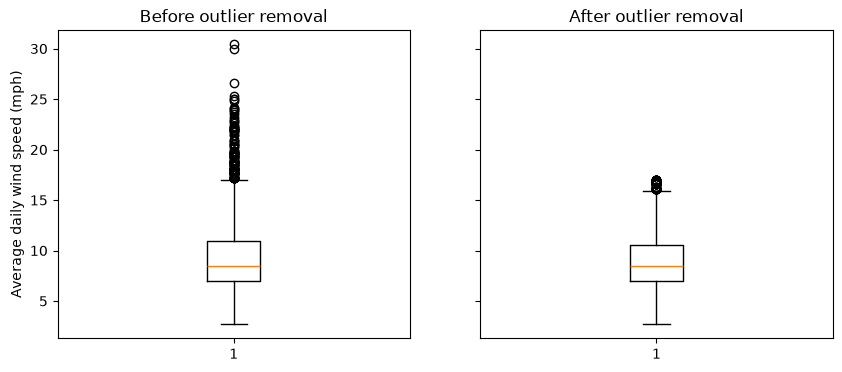

In [22]:
df_iqr = df.drop(outliers.index)
print('rows before:', len(df))
print('rows after: ', len(df_iqr))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
axes[0].boxplot(df[col])
axes[0].set_title('Before outlier removal')
axes[0].set_ylabel('Average daily wind speed (mph)')
axes[1].boxplot(df_iqr[col])
axes[1].set_title('After outlier removal')
plt.show()

#### Standard deviation method on daily high temperature

For comparison, the three-standard-deviation rule flags values more than 3σ from the mean.

In [23]:
mean_t = df['TMAX_F'].mean()
std_t = df['TMAX_F'].std()
low_t = mean_t - 3 * std_t
high_t = mean_t + 3 * std_t
print(f'mean: {mean_t:.2f}  std: {std_t:.2f}  bounds: {low_t:.2f} to {high_t:.2f} °F')

sd_outliers = df[(df['TMAX_F'] < low_t) | (df['TMAX_F'] > high_t)]
print('outliers by 3-sigma rule:', len(sd_outliers))

q1_t, q3_t = df['TMAX_F'].quantile([0.25, 0.75])
iqr_t = q3_t - q1_t
iqr_t_out = df[(df['TMAX_F'] < q1_t - 1.5 * iqr_t) | (df['TMAX_F'] > q3_t + 1.5 * iqr_t)]
print('outliers by IQR rule:    ', len(iqr_t_out))
iqr_t_out[['DATE', 'TMAX_F', 'TMIN_F', 'SNOW_IN']]

mean: 65.47  std: 18.80  bounds: 9.07 to 121.86 °F
outliers by 3-sigma rule: 7
outliers by IQR rule:     7


,DATE,TMAX_F,TMIN_F,SNOW_IN
735,2017-01-05,8.24,1.22,3.110236
2234,2021-02-12,8.24,-1.84,0.314961
2235,2021-02-13,5.18,-1.84,0.590551
2236,2021-02-14,-0.76,-12.82,1.614173
2610,2022-02-23,7.16,-5.80,0.118110
2912,2022-12-22,1.22,-9.76,1.417323
2951,2023-01-30,8.24,-1.84,0.118110


### 3.3 Data Reduction

#### Dimension elimination

The station metadata columns (`STATION`, `NAME`, `LATITUDE`, `LONGITUDE`, `ELEVATION`) hold the same value on every row. The `_ATTRIBUTES` flag columns, the raw tenths-unit columns that now have converted versions, and the weather-type flags are also dropped, leaving the measurements used in the analysis.

In [24]:
print('before:', df.shape)

keep_cols = ['DATE', 'YEAR', 'MONTH', 'SEASON',
             'TMAX_F', 'TMIN_F', 'PRCP_IN', 'SNOW_IN', 'SNWD_IN',
             'AWND_MPH', 'WSF5_MPH', 'RHAV', 'ADPT_F', 'ASLP_HPA']
dropped_dims = [c for c in df.columns if c not in keep_cols]
df_reduced = df[keep_cols].copy()

print('after: ', df_reduced.shape)
print(f'columns removed: {len(dropped_dims)}')
df_reduced.head()

before: (3653, 107)
after:  (3653, 14)
columns removed: 93


,DATE,YEAR,MONTH,SEASON,TMAX_F,TMIN_F,PRCP_IN,SNOW_IN,SNWD_IN,AWND_MPH,WSF5_MPH,RHAV,ADPT_F,ASLP_HPA
0,2015-01-01,2015,1,Winter,24.26,2.12,0.090551,2.007874,0.000000,8.500372,21.922012,69.0,8.06,1022.7
1,2015-01-02,2015,1,Winter,35.96,12.20,0.000000,0.000000,1.968504,5.816044,18.119214,69.0,12.92,1019.3
2,2015-01-03,2015,1,Winter,41.00,9.14,0.000000,0.000000,1.968504,13.197946,42.054472,62.0,12.02,1016.6
3,2015-01-04,2015,1,Winter,30.20,3.20,0.000000,0.000000,1.181102,3.355410,17.000744,71.0,8.96,1031.2
4,2015-01-05,2015,1,Winter,60.98,19.22,0.000000,0.000000,0.000000,9.618842,46.080964,48.0,21.02,1022.7


#### Sampling by number and by percentage

In [25]:
sample_n = df_reduced.sample(n=365, random_state=634)
sample_frac = df_reduced.sample(frac=0.10, random_state=634)

print('original:            ', df_reduced.shape)
print('sample by number:    ', sample_n.shape)
print('sample by percentage:', sample_frac.shape)
sample_frac.head()

original:             (3653, 14)
sample by number:     (365, 14)
sample by percentage: (365, 14)


,DATE,YEAR,MONTH,SEASON,TMAX_F,TMIN_F,PRCP_IN,SNOW_IN,SNWD_IN,AWND_MPH,WSF5_MPH,RHAV,ADPT_F,ASLP_HPA
3502,2024-08-03,2024,8,Summer,93.02,62.06,0.011811,0.0,0.0,6.487126,27.066974,43.0,48.92,1017.3
557,2016-07-11,2016,7,Summer,91.04,62.96,0.000000,0.0,0.0,9.171454,40.936002,26.0,37.04,1003.7
921,2017-07-10,2017,7,Summer,91.94,60.08,0.000000,0.0,0.0,8.724066,23.935258,33.0,44.06,1010.2
385,2016-01-21,2016,1,Winter,42.08,19.22,0.000000,0.0,0.0,11.408394,36.014734,40.0,8.96,1026.1
776,2017-02-15,2017,2,Winter,60.08,21.20,0.000000,0.0,0.0,5.816044,17.000744,36.0,10.94,1021.3


In [26]:
# does a 10% sample keep the shape of the full data
pd.DataFrame({'full mean': df_reduced[['TMAX_F', 'TMIN_F', 'AWND_MPH', 'RHAV']].mean(),
              '10% sample mean': sample_frac[['TMAX_F', 'TMIN_F', 'AWND_MPH', 'RHAV']].mean()}).round(2)

,full mean,10% sample mean
TMAX_F,65.47,66.23
TMIN_F,37.83,38.37
AWND_MPH,9.33,9.13
RHAV,46.97,46.03


### 3.4 Data Scaling and Discretization

#### Before scaling

In [27]:
scaled = df_reduced[['DATE', 'TMAX_F', 'PRCP_IN', 'AWND_MPH']].copy()
scaled[['TMAX_F', 'PRCP_IN', 'AWND_MPH']].describe().round(3)

,TMAX_F,PRCP_IN,AWND_MPH
count,3653.000,3653.000,3653.000
mean,65.466,0.045,9.328
std,18.798,0.177,3.344
min,-0.760,0.000,2.684
25%,51.980,0.000,6.935
50%,66.920,0.000,8.500
75%,80.960,0.000,10.961
max,100.940,4.051,30.422


#### Min-max scaling, z-score standardization, and decimal scaling

* Min-max: (v − min) / (max − min), mapped to [0, 1]
* Z-score: (v − mean) / std
* Decimal scaling: v / 10^j, where j is the number of digits in the largest absolute value

In [28]:
t = scaled['TMAX_F']
scaled['TMAX_MinMax'] = (t - t.min()) / (t.max() - t.min())
scaled['TMAX_Z'] = (t - t.mean()) / t.std()

j = len(str(int(t.abs().max())))
scaled['TMAX_Decimal'] = t / 10 ** j
print('decimal scaling exponent j =', j)

w = scaled['AWND_MPH']
scaled['AWND_MinMax'] = (w - w.min()) / (w.max() - w.min())
scaled['AWND_Z'] = (w - w.mean()) / w.std()

scaled[['TMAX_F', 'TMAX_MinMax', 'TMAX_Z', 'TMAX_Decimal', 'AWND_MPH', 'AWND_MinMax', 'AWND_Z']].head()

decimal scaling exponent j = 3


,TMAX_F,TMAX_MinMax,TMAX_Z,TMAX_Decimal,AWND_MPH,AWND_MinMax,AWND_Z
0,24.26,0.246018,-2.192003,0.02426,8.500372,0.209677,-0.247409
1,35.96,0.361062,-1.569608,0.03596,5.816044,0.112903,-1.050062
2,41.00,0.410619,-1.301499,0.04100,13.197946,0.379032,1.157232
3,30.20,0.304425,-1.876018,0.03020,3.355410,0.024194,-1.785826
4,60.98,0.607080,-0.238641,0.06098,9.618842,0.250000,0.087029


#### After scaling

In [29]:
scaled[['TMAX_MinMax', 'TMAX_Z', 'TMAX_Decimal', 'AWND_MinMax', 'AWND_Z']].describe().round(3)

,TMAX_MinMax,TMAX_Z,TMAX_Decimal,AWND_MinMax,AWND_Z
count,3653.000,3653.000,3653.000,3653.000,3653.000
mean,0.651,-0.000,0.065,0.240,0.000
std,0.185,1.000,0.019,0.121,1.000
min,0.000,-3.523,-0.001,0.000,-1.986
25%,0.519,-0.717,0.052,0.153,-0.716
50%,0.665,0.077,0.067,0.210,-0.247
75%,0.804,0.824,0.081,0.298,0.488
max,1.000,1.887,0.101,1.000,6.308


#### Discretization

Daily high temperature is discretized into four categories with `pd.cut`. Precipitation is discretized with `np.select`, following the class demo.

In [30]:
disc = df_reduced[['DATE', 'TMAX_F', 'PRCP_IN']].copy()

disc['TEMP_CAT'] = pd.cut(disc['TMAX_F'],
                          bins=[-np.inf, 40, 60, 80, np.inf],
                          labels=['Cold (<40°F)', 'Cool (40-60°F)', 'Warm (60-80°F)', 'Hot (≥80°F)'],
                          right=False)

conditions = [disc['PRCP_IN'] < 0.01,
              disc['PRCP_IN'] < 0.10,
              disc['PRCP_IN'] < 0.50]
disc['PRCP_CAT'] = np.select(conditions, ['Dry', 'Light', 'Moderate'], default='Heavy')

print('before discretization:')
print(df_reduced[['DATE', 'TMAX_F', 'PRCP_IN']].head(8))
print()
print('after discretization:')
disc.head(8)

before discretization:
        DATE  TMAX_F   PRCP_IN
0 2015-01-01   24.26  0.090551
1 2015-01-02   35.96  0.000000
2 2015-01-03   41.00  0.000000
3 2015-01-04   30.20  0.000000
4 2015-01-05   60.98  0.000000
5 2015-01-06   55.94  0.000000
6 2015-01-07   37.04  0.011811
7 2015-01-08   59.00  0.000000

after discretization:


,DATE,TMAX_F,PRCP_IN,TEMP_CAT,PRCP_CAT
0,2015-01-01,24.26,0.090551,Cold (<40°F),Light
1,2015-01-02,35.96,0.000000,Cold (<40°F),Dry
2,2015-01-03,41.00,0.000000,Cool (40-60°F),Dry
3,2015-01-04,30.20,0.000000,Cold (<40°F),Dry
4,2015-01-05,60.98,0.000000,Warm (60-80°F),Dry
5,2015-01-06,55.94,0.000000,Cool (40-60°F),Dry
6,2015-01-07,37.04,0.011811,Cold (<40°F),Light
7,2015-01-08,59.00,0.000000,Cool (40-60°F),Dry


In [31]:
print(disc['TEMP_CAT'].value_counts().sort_index())
print()
print(disc['PRCP_CAT'].value_counts())

TEMP_CAT
Cold (<40°F)       394
Cool (40-60°F)     999
Warm (60-80°F)    1223
Hot (≥80°F)       1037
Name: count, dtype: int64

PRCP_CAT
Dry         2747
Light        539
Moderate     290
Heavy         77
Name: count, dtype: int64


## Step 4: Statistical Analysis

The statistics below use the cleaned, dimension-reduced dataset (all 3,653 days, before outlier removal).

### 4.1 General overview

In [32]:
df_reduced.info()

<class 'pandas.DataFrame'>
RangeIndex: 3653 entries, 0 to 3652
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   DATE      3653 non-null   datetime64[us]
 1   YEAR      3653 non-null   int32         
 2   MONTH     3653 non-null   int32         
 3   SEASON    3653 non-null   str           
 4   TMAX_F    3653 non-null   float64       
 5   TMIN_F    3653 non-null   float64       
 6   PRCP_IN   3653 non-null   float64       
 7   SNOW_IN   3653 non-null   float64       
 8   SNWD_IN   3653 non-null   float64       
 9   AWND_MPH  3653 non-null   float64       
 10  WSF5_MPH  3653 non-null   float64       
 11  RHAV      3653 non-null   float64       
 12  ADPT_F    3653 non-null   float64       
 13  ASLP_HPA  3653 non-null   float64       
dtypes: datetime64[us](1), float64(10), int32(2), str(1)
memory usage: 371.1 KB


In [33]:
df_reduced.describe().round(2)

,DATE,YEAR,MONTH,TMAX_F,TMIN_F,PRCP_IN,SNOW_IN,SNWD_IN,AWND_MPH,WSF5_MPH,RHAV,ADPT_F,ASLP_HPA
count,3653,3653.00,3653.00,3653.00,3653.00,3653.00,3653.00,3653.00,3653.00,3653.00,3653.00,3653.00,3653.00
mean,2020-01-01 00:00:00,2019.50,6.52,65.47,37.83,0.05,0.12,0.20,9.33,31.84,46.97,28.35,1015.29
min,2015-01-01 00:00:00,2015.00,1.00,-0.76,-15.88,0.00,0.00,0.00,2.68,10.07,6.00,-13.00,989.20
25%,2017-07-02 00:00:00,2017.00,4.00,51.98,25.16,0.00,0.00,0.00,6.93,23.04,34.00,15.98,1010.80
50%,2020-01-01 00:00:00,2020.00,7.00,66.92,37.04,0.00,0.00,0.00,8.50,31.09,45.00,26.96,1015.20
75%,2022-07-02 00:00:00,2022.00,10.00,80.96,53.06,0.00,0.00,0.00,10.96,38.92,59.00,42.08,1020.00
max,2024-12-31 00:00:00,2024.00,12.00,100.94,69.98,4.05,10.20,11.81,30.42,97.08,97.00,60.98,1040.00
std,NaN,2.87,3.45,18.80,16.18,0.18,0.60,0.87,3.34,11.00,17.44,15.29,7.33


### 4.2 Central tendency

Midrange is computed as (max + min) / 2, the midpoint of the range.

In [34]:
numerical_cols = ['TMAX_F', 'TMIN_F', 'PRCP_IN', 'SNOW_IN', 'AWND_MPH', 'WSF5_MPH', 'RHAV']

def get_central_tendency(col):
    s = df_reduced[col]
    return pd.Series({'min': s.min(),
                      'max': s.max(),
                      'mean': s.mean(),
                      'median': s.median(),
                      'mode': s.mode()[0],
                      'midrange': (s.max() + s.min()) / 2})

central = pd.DataFrame({c: get_central_tendency(c) for c in numerical_cols}).T
central.round(2)

,min,max,mean,median,mode,midrange
TMAX_F,-0.76,100.94,65.47,66.92,87.08,50.09
TMIN_F,-15.88,69.98,37.83,37.04,57.92,27.05
PRCP_IN,0.00,4.05,0.05,0.00,0.00,2.03
SNOW_IN,0.00,10.20,0.12,0.00,0.00,5.10
AWND_MPH,2.68,30.42,9.33,8.50,7.61,16.55
WSF5_MPH,10.07,97.08,31.84,31.09,29.97,53.57
RHAV,6.00,97.00,46.97,45.00,39.00,51.50


### 4.3 Dispersion

Variance and standard deviation use the pandas default, the sample formula (n − 1).

In [35]:
def get_dispersion(col):
    s = df_reduced[col]
    q = s.quantile([0.25, 0.5, 0.75])
    return pd.Series({'range': s.max() - s.min(),
                      'Q1': q[0.25],
                      'Q2': q[0.5],
                      'Q3': q[0.75],
                      'IQR': q[0.75] - q[0.25],
                      'variance': s.var(),
                      'std': s.std()})

dispersion = pd.DataFrame({c: get_dispersion(c) for c in numerical_cols}).T
dispersion.round(2)

,range,Q1,Q2,Q3,IQR,variance,std
TMAX_F,101.70,51.98,66.92,80.96,28.98,353.38,18.80
TMIN_F,85.86,25.16,37.04,53.06,27.90,261.64,16.18
PRCP_IN,4.05,0.00,0.00,0.00,0.00,0.03,0.18
SNOW_IN,10.20,0.00,0.00,0.00,0.00,0.37,0.60
AWND_MPH,27.74,6.93,8.50,10.96,4.03,11.18,3.34
WSF5_MPH,87.02,23.04,31.09,38.92,15.88,121.06,11.00
RHAV,91.00,34.00,45.00,59.00,25.00,304.14,17.44


### 4.4 Correlation analysis

In [36]:
corr_cols = ['TMAX_F', 'TMIN_F', 'PRCP_IN', 'SNOW_IN', 'SNWD_IN', 'AWND_MPH', 'WSF5_MPH', 'RHAV', 'ADPT_F', 'ASLP_HPA']
corr = df_reduced[corr_cols].corr()
corr.round(2)

,TMAX_F,TMIN_F,PRCP_IN,SNOW_IN,SNWD_IN,AWND_MPH,WSF5_MPH,RHAV,ADPT_F,ASLP_HPA
TMAX_F,1.00,0.90,-0.01,-0.31,-0.37,0.01,0.25,-0.45,0.70,-0.42
TMIN_F,0.90,1.00,0.11,-0.21,-0.32,0.06,0.25,-0.17,0.86,-0.37
PRCP_IN,-0.01,0.11,1.00,0.25,0.04,0.05,0.07,0.33,0.23,-0.00
SNOW_IN,-0.31,-0.21,0.25,1.00,0.33,0.05,-0.04,0.29,-0.11,0.05
SNWD_IN,-0.37,-0.32,0.04,0.33,1.00,-0.06,-0.14,0.23,-0.20,0.22
AWND_MPH,0.01,0.06,0.05,0.05,-0.06,1.00,0.72,-0.14,-0.07,-0.42
WSF5_MPH,0.25,0.25,0.07,-0.04,-0.14,0.72,1.00,-0.21,0.11,-0.53
RHAV,-0.45,-0.17,0.33,0.29,0.23,-0.14,-0.21,1.00,0.29,0.35
ADPT_F,0.70,0.86,0.23,-0.11,-0.20,-0.07,0.11,0.29,1.00,-0.17
ASLP_HPA,-0.42,-0.37,-0.00,0.05,0.22,-0.42,-0.53,0.35,-0.17,1.00


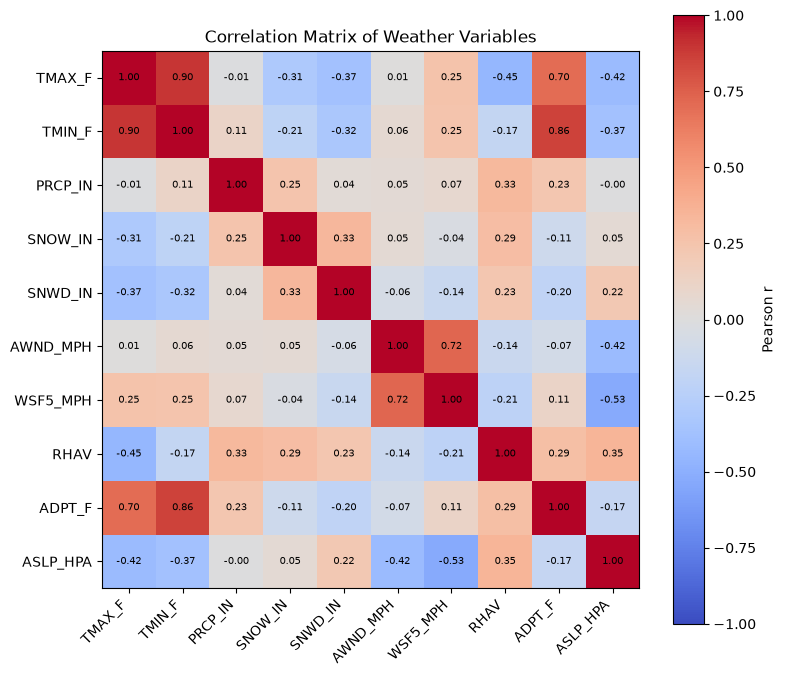

In [37]:
plt.figure(figsize=(8, 7))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Pearson r')
plt.xticks(range(len(corr_cols)), corr_cols, rotation=45, ha='right')
plt.yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for k in range(len(corr_cols)):
        plt.text(k, i, f'{corr.iloc[i, k]:.2f}', ha='center', va='center', fontsize=7)
plt.title('Correlation Matrix of Weather Variables')
plt.tight_layout()
plt.show()

**Insight:** The strongest relationships are between the two temperature columns (r = 0.90), between the daily low and dew point (r = 0.86), and between average wind speed and peak gust (r = 0.72). Sea-level pressure is negatively correlated with peak gust (r = −0.53), consistent with low-pressure storm systems bringing strong wind. Humidity falls as the daily high rises (r = −0.45). Daily precipitation is almost uncorrelated with temperature (r = −0.01), but that number should be read carefully: precipitation is zero on about 3 of every 4 days, and Pearson correlation measures straight-line relationships, so it understates any link for a variable with that many zeros.

## Summary

This lab took ten years of raw NOAA station data from a 108-column file in tenths-of-metric units to a clean 14-column dataset with no missing values. The visualizations showed a strongly seasonal climate with large daily temperature swings, a summer rainfall peak, and high-wind days concentrated in spring. Preprocessing decisions depended on what each gap meant: blank weather flags were filled with 0 because they mean an event did not occur, short sensor gaps were forward filled, and the 28-day humidity outage in February 2015 was filled with the February mean instead of being copied from a single day. The IQR method flagged 118 high-wind days and 7 extreme cold days; both are real weather rather than errors, so they were removed only from a separate DataFrame (`df_iqr`) for comparison, and the statistics in Step 4 use the full dataset.